This is the notebook for cleaning and wrangling the wetlands shapefile. Steps include:
1. Adding the Hectares column and subsetting the data to polygons larger than 1 Hectare.
2. Removing shapefile length, shapefile area, and QAQC. 

In [1]:
# import packages
import platform
from pathlib import Path
import pandas as pd
import geopandas as gpd

Access Initial Shapefile from Box Drive and read in the shapefile

In [2]:
# set a path to the main box folder based on machine's os
# if windows: 
if platform.system() == 'Windows':
    box_path = Path.home() / 'Box'
# if mac:
else:
    box_path = Path.home() / "Library" / "CloudStorage" / "Box-Box"

#Confirm that the box path is valid
if box_path.exists():
    print(f'Box folder found at {box_path}')
else:
    print(f'Failed to locate the Box folder.\nIs the BoxDrive app running?\nAre you logged in?')

# create path object that goes to the specific folder on Box drive
# uploading wetlands that are bigger than a hectare
wetlands_path = box_path / 'ENVIRON 712L-Students' / 'Data' / 'BunkerAndersonTseng' / 'wetlands' / 'wetlands.shp'
print(wetlands_path.exists())



Box folder found at /Users/masonbunker/Library/CloudStorage/Box-Box
True


In [3]:
#read in shp, be PATIENT (took MB 4.5 mins)
wetlands_shp = gpd.read_file(wetlands_path)

Find out information from the wetlands shapefile

In [4]:
wetlands_shp.shape
wetlands_shp.columns


Index(['OBJECTID', 'ATTRIBUTE', 'WETLAND_TY', 'QAQC_CODE', 'ACRES', 'NWI_ID',
       'Shape_Leng', 'Shape_Area', 'geometry'],
      dtype='str')

In [5]:
wetlands_shp.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 891086 entries, 0 to 891085
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   OBJECTID    891086 non-null  float64 
 1   ATTRIBUTE   891086 non-null  str     
 2   WETLAND_TY  891086 non-null  str     
 3   QAQC_CODE   22260 non-null   str     
 4   ACRES       891086 non-null  float64 
 5   NWI_ID      891086 non-null  str     
 6   Shape_Leng  891086 non-null  float64 
 7   Shape_Area  891086 non-null  float64 
 8   geometry    891086 non-null  geometry
dtypes: float64(4), geometry(1), str(4)
memory usage: 61.2 MB


Subset the data to only include polygons larger than 1 Hectare (10,000m^2), roughly 20% of the initial data set.

In [6]:
wetlands_shp["Hectares"] = wetlands_shp["Shape_Area"]/10000

wetlands_hectare = wetlands_shp.loc[lambda df: df["Hectares"] > 1]

wetlands_hectare.shape

#calculate subset percent
subset = 179139/891086*100
print(subset)

20.103446805358853


Determine appropriate columns to remain in the cleaned dataset.

In [7]:
wetlands_hectare.head()

,OBJECTID,ATTRIBUTE,WETLAND_TY,QAQC_CODE,ACRES,NWI_ID,Shape_Leng,Shape_Area,geometry,Hectares
2,3.0,R4SBC,Riverine,NaN,9.394554,202409CSw{B818AEF7-DD4D-43B6-A532-1DC94D248F88...,12669.925427,38018.410790,"POLYGON ((-2195423.854 1489042.416, -2195423.8...",3.801841
9,10.0,R4SBC,Riverine,NaN,4.869321,202409CSw{80E28DA5-6244-45AB-9DC9-774ACABD2846...,6572.482823,19705.442594,"POLYGON ((-2197428.286 1494975.476, -2197428.3...",1.970544
11,12.0,R4SBC,Riverine,NaN,7.364585,202409CSw{A66FA93B-E12A-488A-9891-E7526D1AACCE...,9937.020983,29803.416122,"POLYGON ((-2193923.26 1496246.62, -2193923.139...",2.980342
12,13.0,R4SBC,Riverine,NaN,3.099673,202409CSw{B5A926CC-AF98-487F-A4B9-A4789311100A...,4194.847948,12543.932403,"POLYGON ((-2194477.48 1496368.039, -2194475.19...",1.254393
14,15.0,R4SBC,Riverine,NaN,20.027313,202409CSw{C99C89FF-6622-43DE-A93F-138503071611...,26989.063820,81047.662073,"POLYGON ((-2195115.466 1496641.214, -2195115.3...",8.104766


Subset to only Core Columns and rename to be more appropriate

In [8]:
core_cols = ["ATTRIBUTE", "WETLAND_TY","Hectares", "NWI_ID", "geometry"]

wetlands = wetlands_hectare[core_cols]

In [54]:
wetlands = wetlands.rename(
    columns={
        "ATTRIBUTE" : "C Code",
        "WETLAND_TY" : "C Type",
        "NWI_ID": "NWI ID"
    }
)

wetlands.head()
wetlands.shape

(179139, 9)

Write a function to fill in the columns for Cowardin (C) Subsystem and Class

In [24]:
# create additional columns for subsystem and class
#wetlands.insert(2, "C Subsystem", None)
#wetlands.insert(3, "C Class", None)

wetlands.head()

,C Code,C System,Hectares,C Subsystem,C Class,C_Subsystem,C_Class,NWI ID,geometry
2,R4SBC,Riverine,3.801841,None,None,None,None,202409CSw{B818AEF7-DD4D-43B6-A532-1DC94D248F88...,"POLYGON ((-2195423.854 1489042.416, -2195423.8..."
9,R4SBC,Riverine,1.970544,None,None,None,None,202409CSw{80E28DA5-6244-45AB-9DC9-774ACABD2846...,"POLYGON ((-2197428.286 1494975.476, -2197428.3..."
11,R4SBC,Riverine,2.980342,None,None,None,None,202409CSw{A66FA93B-E12A-488A-9891-E7526D1AACCE...,"POLYGON ((-2193923.26 1496246.62, -2193923.139..."
12,R4SBC,Riverine,1.254393,None,None,None,None,202409CSw{B5A926CC-AF98-487F-A4B9-A4789311100A...,"POLYGON ((-2194477.48 1496368.039, -2194475.19..."
14,R4SBC,Riverine,8.104766,None,None,None,None,202409CSw{C99C89FF-6622-43DE-A93F-138503071611...,"POLYGON ((-2195115.466 1496641.214, -2195115.3..."


In [45]:
# generate function to determine the Marine Subsystems
def assign_subsystem(df):
    # marine
    wetlands.loc[lambda df: df["C Code"].str.startswith("M1", na = False), "C Subsystem"] = 'Subtidal'
    wetlands.loc[lambda df: df["C Code"].str.startswith("M2", na = False), "C Subsystem"] = 'Intertidal' 
    # estuarine
    wetlands.loc[lambda df: df["C Code"].str.startswith("E1", na = False), "C Subsystem"] = 'Subtidal'
    wetlands.loc[lambda df: df["C Code"].str.startswith("E2", na = False), "C Subsystem"] = 'Intertidal' 
    # riverine
    wetlands.loc[lambda df: df["C Code"].str.startswith("R1", na = False), "C Subsystem"] = 'Tidal'
    wetlands.loc[lambda df: df["C Code"].str.startswith("R2", na = False), "C Subsystem"] = 'Lower Perennial'
    wetlands.loc[lambda df: df["C Code"].str.startswith("R3", na = False), "C Subsystem"] = 'Upper Perennial'
    wetlands.loc[lambda df: df["C Code"].str.startswith("R4", na = False), "C Subsystem"] = 'Intermittent'
    wetlands.loc[lambda df: df["C Code"].str.startswith("R4", na = False), "C Subsystem"] = 'Unknown Perennial'

    # lacustrine
    wetlands.loc[lambda df: df["C Code"].str.startswith("L1", na = False), "C Subsystem"] = 'Limnetic'
    wetlands.loc[lambda df: df["C Code"].str.startswith("L4", na = False), "C Subsystem"] = 'Littoral'
    # palustrine
    wetlands.loc[lambda df: df["C Code"].str.startswith("P", na = False), "C Subsystem"] = "N/A"
    
    return df

#def assign_class(df):
#    df.loc[df["Cowardin"].str.startswith("PEM", na=False), "class"] = "Emergent"

In [50]:
## apply the subsystem function
wetlands1 = assign_subsystem(wetlands)

wetlands1.sample(12)

,C Code,C System,Hectares,C Subsystem,C Class,C_Subsystem,C_Class,NWI ID,geometry
321260,L2USJ,Lake,18.783375,None,None,None,None,202409CSw{09808EE0-5D38-403C-B7E4-41A089A4093E...,"POLYGON ((-1895910.969 1534212.258, -1895906.8..."
374997,PEM1F,Freshwater Emergent Wetland,9.425635,N/A,None,None,None,202409CSw{C78DD5DC-12F4-4A41-97C4-DD1D8F8CF41D...,"POLYGON ((-1923428.708 1710979.496, -1923423.2..."
438542,L2UBK1,Lake,20.014285,None,None,None,None,202409CSw{0D04AD1C-036E-4C66-8173-E69637CCBB4F...,"POLYGON ((-2250299.947 1918088.231, -2250308.4..."
467462,PEM1C,Freshwater Emergent Wetland,1.882995,N/A,None,None,None,202409CSw{40BD2FCF-058F-463E-AB29-7B0254DE356C...,"POLYGON ((-2292619.501 2038538.582, -2292611.4..."
539918,PEM1C,Freshwater Emergent Wetland,1.053738,N/A,None,None,None,202409CSw{2D4EFFC0-EF3F-4193-B7F9-EEC6C23A8F7E...,"POLYGON ((-2192105.563 1853771.59, -2192098.41..."
665600,PEM1C,Freshwater Emergent Wetland,4.543671,N/A,None,None,None,202409CSw{738CAE99-6F57-4305-8F4D-4E685DAC05A0...,"POLYGON ((-2070442.898 2139268.618, -2070440.8..."
127519,R4SBC,Riverine,1.892433,Unknown Perennial,None,None,None,202409CSw{8E137BA9-8883-4D91-9DB9-65E6FBD5E7B9...,"POLYGON ((-2154981.206 1728011.127, -2154986.9..."
705046,PFO,Freshwater Forested/Shrub Wetland,3.616642,N/A,None,None,None,202409CSw{471DA787-616B-40A3-8BD3-54B946A07BE7...,"POLYGON ((-2312844.041 2305154.506, -2312846.9..."
471482,PFO1A,Freshwater Forested/Shrub Wetland,14.913586,N/A,None,None,None,202409CSw{CD773686-219F-46A6-AA6E-F2ED963E935B...,"POLYGON ((-2287133.363 2070165.865, -2287130.2..."
670088,R4SBC,Riverine,1.304971,Unknown Perennial,None,None,None,202409CSw{F35EBAFD-25E5-41B4-B229-2DC852EF62E3...,"POLYGON ((-2093735.534 2117929.57, -2093736.83..."


Look at the data breakdown thus far

<Axes: xlabel='C System'>

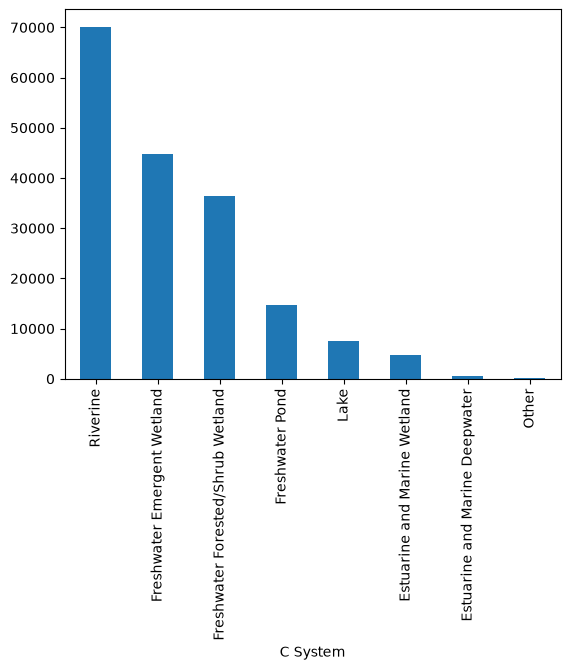

In [53]:
wetlands1["C System"].value_counts().plot(kind="bar")


<Axes: xlabel='C Subsystem'>

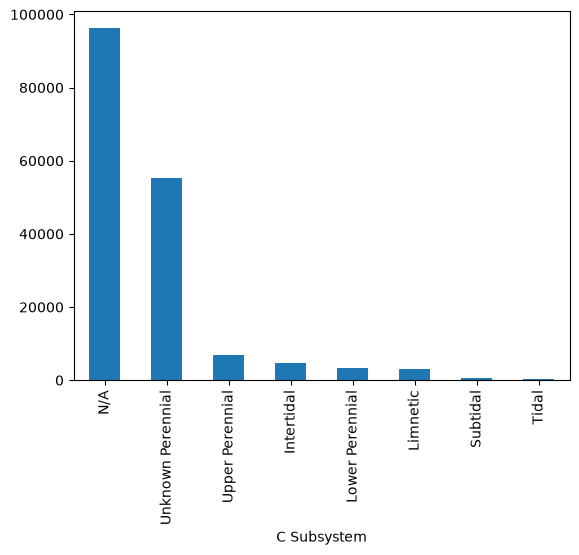

In [ ]:
wetlands1["C Subsystem"].value_counts().plot(kind="bar")
